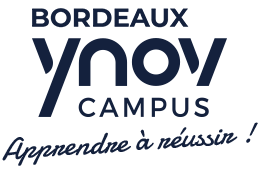

# TP2 — Réseau à L couches : NumPy → PyTorch → Keras

> **Cours Deep Learning · Ynov Bordeaux · EIA Mastère 2** — TP2 (J2)
> 2h05 en séance (4h50 de contenu : parties D à H pour ceux qui finissent en avance) · Résultat attendu en fin de séance : notebook + tableau comparatif (précision dev, temps, lignes de code)

**Comment travailler :** exécutez les cellules dans l'ordre. Les cellules marquées `# TODO` sont à compléter. Utilisez `assert` sur les formes dès que vous manipulez des tenseurs. Une cellule à compléter échoue tant que son `TODO` n'est pas fait : c'est normal. Le TP se termine en séance et le corrigé est distribué en fin de TP ; il n'y a rien à rendre.

## Partie 0 — Cadrer avant de coder (5 min)

Mêmes réflexes qu'au TP1, sur un problème plus grand : **dix vêtements** au lieu de deux. Répondez en commentaire, puis mesurez la baseline la plus simple qui tienne compte du contenu des images : le **centroïde le plus proche** (on compare chaque image à l'image moyenne de chaque classe, calculée au TP1). Tout réseau de la journée devra la battre nettement.

**Organisation du TP (2 h 05 en séance)** : les parties A, B et C sont le tronc commun, à finir en séance ; les parties D à H (« pour ceux qui finissent en avance ») prolongent le TP jusqu'à 4 h 50 de contenu, dans l'ordre que vous voulez. Rien n'est à rendre ; le corrigé complet est distribué en fin de TP.

In [26]:
import os; os.environ.setdefault("MKL_THREADING_LAYER", "TBB")   # évite le crash « OMP Error #15 » (MKL de NumPy + libomp de PyTorch) ; à exécuter avant tout import
import numpy as np, matplotlib.pyplot as plt, time, math
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("device :", device, "| torch", torch.__version__)

device : cuda | torch 2.11.0+cu128


In [27]:
# Fashion-MNIST : 70 000 images 28 x 28 en niveaux de gris, 10 classes. Via torchvision si disponible, sinon via scikit-learn (OpenML).
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
try:
    from torchvision import datasets
    train_ds = datasets.FashionMNIST("data", train=True, download=True)
    test_ds  = datasets.FashionMNIST("data", train=False, download=True)
    X_all = train_ds.data.numpy().reshape(len(train_ds), -1).astype("float32") / 255.0   # (60000, 784), pixels ramenés dans [0, 1]
    y_all = train_ds.targets.numpy()
    X_test = test_ds.data.numpy().reshape(len(test_ds), -1).astype("float32") / 255.0
    y_test = test_ds.targets.numpy()
except ImportError:
    from sklearn.datasets import fetch_openml
    fm = fetch_openml("Fashion-MNIST", version=1, as_frame=False, parser="auto")        # 70 000 x 784, téléchargement de 30 Mo
    Xf = fm.data.astype("float32") / 255.0; yf = fm.target.astype(int)
    X_all, y_all, X_test, y_test = Xf[:60000], yf[:60000], Xf[60000:], yf[60000:]
# split train / dev (le test reste intouché jusqu'à la fin)
rng = np.random.default_rng(0); idx = rng.permutation(len(X_all))
X_train, y_train = X_all[idx[:50000]], y_all[idx[:50000]]
X_dev,   y_dev   = X_all[idx[50000:]], y_all[idx[50000:]]
print(X_train.shape, X_dev.shape, X_test.shape, CLASSES)

(50000, 784) (10000, 784) (10000, 784) ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [28]:
# 1. Apprentissage supervisé : classification multiclasse (10 classes de vêtements), données étiquetées.
# 2. Métrique d'apprentissage : entropie croisée (différentiable, minimisée par descente de gradient).
#    Métrique de décision : accuracy (classe = argmax des probabilités softmax), non différentiable.
# 3. Baselines : hasard / classe majoritaire ≈ 10 % (classes équilibrées) ; centroïde le plus proche ≈ 68 % ;
#    le réseau doit la battre nettement (≈ 86–89 %).
# 4. Cours : X (n_x, m) = (784, m), Y one-hot (10, m) ; exemples en colonnes.
#    PyTorch / Keras : X (m, 784), Y (m,) d'entiers (ou (m, 10) one-hot) ; exemples en lignes.

centroids = np.stack([X_train[y_train == k].mean(axis=0) for k in range(10)])   # (10, 784)
# ||x-c||² = ||x||² - 2x·c + ||c||² : on garde les trois termes pour avoir de vraies distances (N_dev, 10)
d2 = (X_dev**2).sum(axis=1, keepdims=True) - 2 * X_dev @ centroids.T + (centroids**2).sum(axis=1)
acc_centroide = (d2.argmin(axis=1) == y_dev).mean()

assert centroids is not None and centroids.shape == (10, 784) and 0.5 < acc_centroide < 0.8
print(acc_centroide)

0.6859


## Partie A — Réseau à L couches en NumPy (55 min)

Convention du cours : `X` de forme `(n_x, m)`, `Y` one-hot de forme `(10, m)`. ReLU en couches cachées, softmax en sortie. Le réseau du fil rouge : **784 → 128 → 64 → 10**, 109 386 paramètres.

Vous écrivez cinq fonctions : `init_params`, `forward`, `backward`, `update`, `train_np`. Chacune est testée par des `assert` sur les formes avant de passer à la suivante : c'est le réflexe n° 1 de la journée.

In [29]:
# one_hot : y de forme (m,) avec des entiers 0..9  ->  Y de forme (10, m) avec un 1 sur la ligne de la bonne classe.
# L'indexation avancée Y[y, arange(m)] écrit les m « 1 » d'un coup : ligne = classe, colonne = exemple.
def one_hot(y, C=10):
    Y = np.zeros((C, len(y))); Y[y, np.arange(len(y))] = 1; return Y
# 20 000 images d'entraînement suffisent pour la journée (le réseau atteint 86 % ; avec 50 000 on gagnerait 1 à 2 points).
# .T : la convention du cours, un exemple par colonne. float64 pour que les vérifications numériques soient précises.
Xtr, Ytr = X_train[:20000].T.astype("float64"), one_hot(y_train[:20000])
Xdv, Ydv = X_dev.T.astype("float64"), one_hot(y_dev)
print(Xtr.shape, Ytr.shape, "| un exemple :", Ytr[:, 0], "-> classe", y_train[0], CLASSES[y_train[0]])

(784, 20000) (10, 20000) | un exemple : [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.] -> classe 7 Sneaker


### A1. Initialisation (He) et dimensions
Pour chaque couche l : `W[l]` de forme `(n[l], n[l-1])`, `b[l]` de forme `(n[l], 1)`. Les poids sont tirés au hasard (pour casser la symétrie) avec l'écart-type de He, `sqrt(2 / n[l-1])`, adapté à ReLU.

In [30]:
def init_params(layer_dims, seed=0):
    rng = np.random.default_rng(seed); params = {}
    for l in range(1, len(layer_dims)):
        n_l, n_prev = layer_dims[l], layer_dims[l-1]
        params[f"W{l}"] = rng.standard_normal((n_l, n_prev)) * np.sqrt(2 / n_prev)   # He, forme (n_l, n_prev)
        params[f"b{l}"] = np.zeros((n_l, 1))
    return params
dims = [784, 128, 64, 10]; params = init_params(dims)
for l in range(1, 4): assert params[f"W{l}"].shape == (dims[l], dims[l-1]) and params[f"b{l}"].shape == (dims[l], 1)
n_params = sum(p.size for p in params.values())
assert n_params == 109_386, n_params        # le nombre de la slide « Compter les paramètres »

### A2. Passe avant avec cache, softmax, coût
Chaque couche calcule `Z = W @ A_prev + b` puis `A = g(Z)` : ReLU pour les couches cachées, softmax pour la dernière. On **garde en cache** `(A_prev, Z)` de chaque couche : la passe arrière en aura besoin, exactement comme sur la slide de l'appartement à neuf paramètres.

In [31]:
def relu(Z): return np.maximum(0, Z)
def softmax(Z):
    Z = Z - Z.max(axis=0, keepdims=True)
    E = np.exp(Z); return E / E.sum(axis=0, keepdims=True)

def forward(X, params, L):
    A, caches = X, []
    for l in range(1, L + 1):
        Z = params[f"W{l}"] @ A + params[f"b{l}"]
        A_prev, A = A, (softmax(Z) if l == L else relu(Z))
        caches.append((A_prev, Z))
    return A, caches

def cost(AL, Y): return -np.sum(Y * np.log(AL + 1e-12)) / Y.shape[1]    # entropie croisée moyenne

AL, caches = forward(Xtr[:, :5], params, 3)
assert AL.shape == (10, 5) and np.allclose(AL.sum(axis=0), 1)
print(cost(AL, Ytr[:, :5]), ": de l'ordre de log 10 =", np.log(10))

2.812883661992328 : de l'ordre de log 10 = 2.302585092994046


### A3. Passe arrière et mise à jour
Les trois gestes de la matinée, couche par couche, de la sortie vers l'entrée :
- **sortie** : `dZ[L] = AL − Y` (softmax + entropie croisée : le 2 de l'erreur quadratique a disparu) ;
- **descendre aux poids** : `dW[l] = dZ[l] @ A_prev.T / m`, `db[l] = moyenne de dZ[l] sur les colonnes` ;
- **répartir puis passer le pli** : `dZ[l-1] = (W[l].T @ dZ[l]) * (Z[l-1] > 0)`.

Puis `update` : chaque paramètre ← lui-même − α × sa pente.

In [32]:
def backward(AL, Y, params, caches, L):
    m = Y.shape[1]; grads = {}; dZ = AL - Y
    for l in range(L, 0, -1):
        A_prev, Z = caches[l - 1]
        grads[f"dW{l}"] = dZ @ A_prev.T / m
        grads[f"db{l}"] = dZ.mean(axis=1, keepdims=True)
        assert grads[f"dW{l}"].shape == params[f"W{l}"].shape
        if l > 1: dZ = (params[f"W{l}"].T @ dZ) * (caches[l - 2][1] > 0)
    return grads

def update(params, grads, alpha, L):
    for l in range(1, L + 1):
        params[f"W{l}"] -= alpha * grads[f"dW{l}"]
        params[f"b{l}"] -= alpha * grads[f"db{l}"]
    return params

def predict_np(X, params, L): return forward(X, params, L)[0].argmax(axis=0)

# Test : une mise à jour (alpha = 0,1) sur un batch de 128 images doit faire baisser le coût sur ce batch.
Xb, Yb = Xtr[:, :128], Ytr[:, :128]; p = init_params(dims)
J0 = cost(forward(Xb, p, 3)[0], Yb)
AL_b, caches_b = forward(Xb, p, 3); p = update(p, backward(AL_b, Yb, p, caches_b, 3), 0.1, 3)
J1 = cost(forward(Xb, p, 3)[0], Yb)
assert J1 < J0, (J0, J1)

### A4. Entraînement par mini-batchs
Une **epoch** = une passe sur les 20 000 images, par **mini-batchs** de 128 colonnes mélangées. À chaque batch : forward → coût → backward → update. À chaque epoch : coût moyen et accuracy dev. Objectif : ~86 % dev en 15 epochs, en quelques secondes.

In [33]:
def train_np(Xtr, Ytr, Xdv, ydv, dims, alpha=0.1, epochs=15, batch=128, seed=0, init=None, verbose=True):
    L = len(dims) - 1; m = Xtr.shape[1]; rng = np.random.default_rng(seed)
    params = init(dims, seed) if init else init_params(dims, seed)
    hist = {"J": [], "acc_dev": []}
    for e in range(epochs):
        perm = rng.permutation(m); Js = []
        for i in range(0, m, batch):
            idx = perm[i:i + batch]
            AL, caches = forward(Xtr[:, idx], params, L); Js.append(cost(AL, Ytr[:, idx]))
            params = update(params, backward(AL, Ytr[:, idx], params, caches, L), alpha, L)
        hist["J"].append(float(np.mean(Js))); hist["acc_dev"].append(float((predict_np(Xdv, params, L) == ydv).mean()))
        if verbose: print(f"epoch {e+1:2d} | J {hist['J'][-1]:.3f} | acc dev {hist['acc_dev'][-1]:.4f}")
    return params, hist

t0 = time.perf_counter()
params, hist_np = train_np(Xtr, Ytr, Xdv, y_dev, dims, alpha=0.1, epochs=15)
time_np = time.perf_counter() - t0; acc_np = hist_np["acc_dev"][-1]
assert acc_np > 0.80

epoch  1 | J 0.848 | acc dev 0.7858
epoch  2 | J 0.559 | acc dev 0.7803
epoch  3 | J 0.493 | acc dev 0.7865
epoch  4 | J 0.450 | acc dev 0.8284
epoch  5 | J 0.426 | acc dev 0.7379
epoch  6 | J 0.406 | acc dev 0.8455
epoch  7 | J 0.390 | acc dev 0.7438
epoch  8 | J 0.372 | acc dev 0.8453
epoch  9 | J 0.362 | acc dev 0.8310
epoch 10 | J 0.345 | acc dev 0.7905
epoch 11 | J 0.340 | acc dev 0.7758
epoch 12 | J 0.334 | acc dev 0.8325
epoch 13 | J 0.326 | acc dev 0.8241
epoch 14 | J 0.311 | acc dev 0.8669
epoch 15 | J 0.306 | acc dev 0.8573


### A5. Lire les courbes
Tracez le coût et l'accuracy dev par epoch : le coût part de 2,30 (log 10, le hasard) et doit décroître vite puis ralentir ; l'accuracy doit dépasser largement la baseline centroïde.

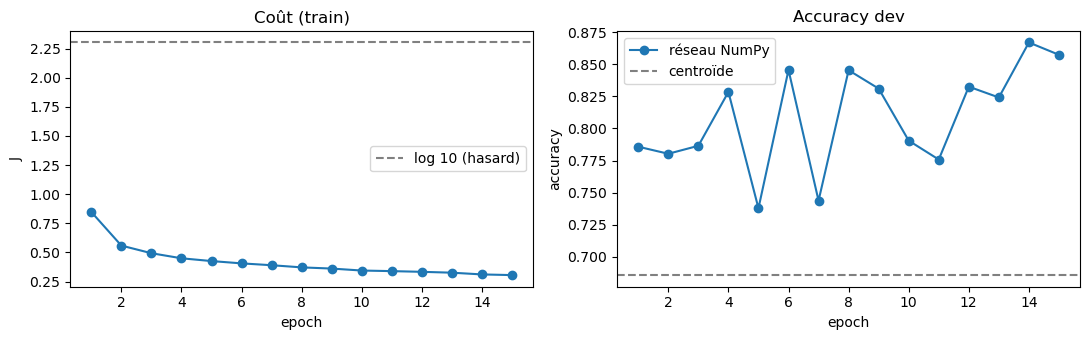

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5)); ep = np.arange(1, len(hist_np["J"]) + 1)
ax[0].plot(ep, hist_np["J"], marker="o"); ax[0].axhline(np.log(10), color="gray", ls="--", label="log 10 (hasard)")
ax[0].set(title="Coût (train)", xlabel="epoch", ylabel="J"); ax[0].legend()
ax[1].plot(ep, hist_np["acc_dev"], marker="o", label="réseau NumPy"); ax[1].axhline(acc_centroide, color="gray", ls="--", label="centroïde")
ax[1].set(title="Accuracy dev", xlabel="epoch", ylabel="accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

## Partie B — Le même réseau en PyTorch (40 min)

Maintenant les vrais outils : `Dataset`/`DataLoader` pour les mini-batchs, `nn.Module` pour le modèle, la boucle en cinq lignes. Attention à la convention inversée : `(m, 784)` et `nn.Linear(784, 128)` stocke un poids de forme `(128, 784)`, la même que votre `W1`.

In [35]:
# DataLoader : découpe le TensorDataset en mini-batchs de 128, mélangés à chaque epoch (shuffle=True) ; c'est votre `perm` de A4.
Xt = torch.tensor(X_train[:20000]); yt = torch.tensor(y_train[:20000], dtype=torch.long)    # (m, 784) : convention framework
Xd = torch.tensor(X_dev); yd = torch.tensor(y_dev, dtype=torch.long)
train_loader = DataLoader(TensorDataset(Xt, yt), batch_size=128, shuffle=True)
dev_loader = DataLoader(TensorDataset(Xd, yd), batch_size=1000)
xb, yb = next(iter(train_loader)); print("un batch :", xb.shape, yb.shape, "| nombre de batchs par epoch :", len(train_loader))

un batch : torch.Size([128, 784]) torch.Size([128]) | nombre de batchs par epoch : 157


### B1. Le modèle : `MLP(nn.Module)`
`nn.Sequential` de `Linear` + `ReLU`, dernière couche **sans softmax** (logits). Vérifiez que vous retrouvez 109 386 paramètres et la forme `(128, 784)` du premier poids.

In [36]:
class MLP(nn.Module):
    def __init__(self, n_in=784, hidden=(128, 64), n_out=10):
        super().__init__()
        dims = [n_in, *hidden, n_out]; layers = []
        for i in range(len(dims) - 1):
            lin = nn.Linear(dims[i], dims[i + 1])
            nn.init.kaiming_normal_(lin.weight, nonlinearity="relu"); nn.init.zeros_(lin.bias)
            layers.append(lin)
            if i < len(dims) - 2: layers.append(nn.ReLU())
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

model = MLP()
n_pt = sum(p.numel() for p in model.parameters()); assert n_pt == 109_386, n_pt
assert model.net[0].weight.shape == (128, 784)

### B2. Évaluer et entraîner
`evaluate` : `model.eval()`, `torch.no_grad()`, accuracy sur un loader. `train_torch` : la boucle en cinq lignes (forward → loss → zero_grad → backward → step), `model.train()` au début de chaque epoch, historique du coût et de l'accuracy dev.

In [37]:
def evaluate(model, loader):
    model.eval(); correct = n = 0
    with torch.no_grad():
        for xb, yb in loader:
            pred = model(xb.to(device)).argmax(dim=1)
            correct += (pred == yb.to(device)).sum().item(); n += len(yb)
    return correct / n

def train_torch(model, train_loader, dev_loader, epochs=15, lr=0.1, opt_cls=torch.optim.SGD, verbose=True):
    model.to(device); opt = opt_cls(model.parameters(), lr=lr); loss_fn = nn.CrossEntropyLoss()
    hist = {"J": [], "acc_dev": []}
    for e in range(epochs):
        model.train(); Js = []
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = loss_fn(model(xb), yb); opt.zero_grad(); loss.backward(); opt.step(); Js.append(loss.item())
        hist["J"].append(float(np.mean(Js))); hist["acc_dev"].append(evaluate(model, dev_loader))
        if verbose: print(f"epoch {e+1:2d} | J {hist['J'][-1]:.3f} | acc dev {hist['acc_dev'][-1]:.4f}")
    return hist

model = MLP()
t0 = time.perf_counter(); hist_pt = train_torch(model, train_loader, dev_loader, epochs=15, lr=0.1); time_pt = time.perf_counter() - t0
acc_pt = hist_pt["acc_dev"][-1]; assert acc_pt > 0.80

epoch  1 | J 0.848 | acc dev 0.7771
epoch  2 | J 0.561 | acc dev 0.7582
epoch  3 | J 0.493 | acc dev 0.8188
epoch  4 | J 0.452 | acc dev 0.7361
epoch  5 | J 0.429 | acc dev 0.8441
epoch  6 | J 0.406 | acc dev 0.8025
epoch  7 | J 0.389 | acc dev 0.8028
epoch  8 | J 0.377 | acc dev 0.7928
epoch  9 | J 0.365 | acc dev 0.8373
epoch 10 | J 0.347 | acc dev 0.8510
epoch 11 | J 0.340 | acc dev 0.7861
epoch 12 | J 0.335 | acc dev 0.8016
epoch 13 | J 0.323 | acc dev 0.8604
epoch 14 | J 0.317 | acc dev 0.8293
epoch 15 | J 0.308 | acc dev 0.8570


### B3. Sauvegarder, recharger, prédire une image
Le `state_dict` est le dictionnaire des paramètres (vos `W1`, `b1`… sous d'autres noms). C'est ce que vous déploierez au projet (J4). Rechargez-le dans un modèle neuf et vérifiez qu'il donne les mêmes prédictions ; puis affichez les dix probabilités d'une image du dev.

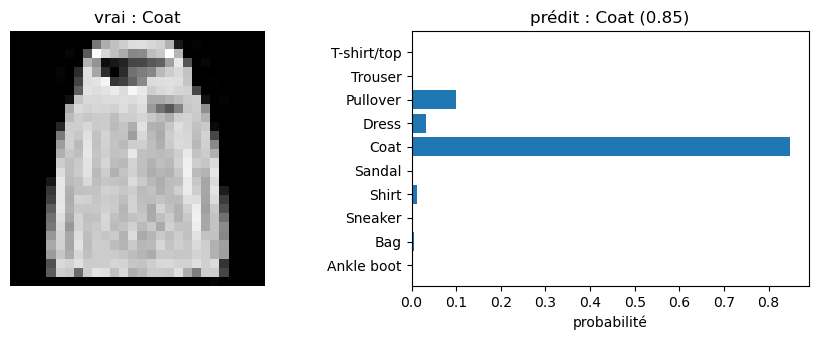

In [38]:
torch.save(model.state_dict(), "mlp_fashion.pt")
model2 = MLP(); model2.load_state_dict(torch.load("mlp_fashion.pt")); model2.to(device)
assert model2 is not None and evaluate(model2, dev_loader) == evaluate(model, dev_loader) > 0.8
i = 7; model2.eval()
with torch.no_grad(): probs = torch.softmax(model2(Xd[i:i+1].to(device)), dim=1)[0].cpu().numpy()
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].imshow(X_dev[i].reshape(28, 28), cmap="gray"); ax[0].set_title(f"vrai : {CLASSES[y_dev[i]]}"); ax[0].axis("off")
ax[1].barh(CLASSES, probs); ax[1].invert_yaxis(); ax[1].set(title=f"prédit : {CLASSES[probs.argmax()]} ({probs.max():.2f})", xlabel="probabilité")
plt.tight_layout(); plt.show()

## Partie C — Le même réseau en Keras (25 min)

Style déclaratif : `Sequential`, `compile`, `fit`. Keras 3 utilise PyTorch comme backend (`KERAS_BACKEND=torch`, fixé ci-dessous ; si Keras n'est pas installé : `pip install keras`).

### C1. Déclarer, compiler, entraîner (15 min)
Reproduisez l'architecture, l'initialisation He, SGD 0,1, 15 epochs, batch 128, et comparez `model.summary()` à vos 109 386 paramètres. Ne vous étonnez pas si l'accuracy dev de la dernière epoch diffère de quelques points de celle de PyTorch : avec SGD 0,1 sans momentum, l'accuracy dev oscille de ±5 points au fil des mini-batchs d'une même epoch (relisez les colonnes « acc dev » des parties A et B), et la valeur lue à la dernière epoch est un tirage dans ce bruit ; à poids initiaux identiques et sans mélange des batchs, Keras et PyTorch donnent la même courbe à la précision flottante près.

In [39]:
import os; os.environ.setdefault("KERAS_BACKEND", "torch")
import keras
from keras import layers
keras.utils.set_random_seed(0)
k_model = keras.Sequential([layers.Input((784,)),
                            layers.Dense(128, activation="relu", kernel_initializer="he_normal"),
                            layers.Dense(64, activation="relu", kernel_initializer="he_normal"),
                            layers.Dense(10, kernel_initializer="he_normal")])
k_model.compile(optimizer=keras.optimizers.SGD(0.1), loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
k_model.summary()
t0 = time.perf_counter()
h_k = k_model.fit(X_train[:20000], y_train[:20000], epochs=15, batch_size=128, validation_data=(X_dev, y_dev), verbose=2)
time_k = time.perf_counter() - t0
acc_k = h_k.history["val_accuracy"][-1]; acc_k_max = max(h_k.history["val_accuracy"]); hist_k = h_k.history["loss"]
assert k_model.count_params() == 109_386

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
157/157 - 1s - 8ms/step - accuracy: 0.7086 - loss: 0.8419 - val_accuracy: 0.7733 - val_loss: 0.6352
Epoch 2/15
157/157 - 1s - 6ms/step - accuracy: 0.7934 - loss: 0.5704 - val_accuracy: 0.7691 - val_loss: 0.6318
Epoch 3/15
157/157 - 1s - 7ms/step - accuracy: 0.8213 - loss: 0.4961 - val_accuracy: 0.7820 - val_loss: 0.6337
Epoch 4/15
157/157 - 1s - 7ms/step - accuracy: 0.8362 - loss: 0.4577 - val_accuracy: 0.7810 - val_loss: 0.5918
Epoch 5/15
157/157 - 1s - 8ms/step - accuracy: 0.8422 - loss: 0.4320 - val_accuracy: 0.8081 - val_loss: 0.5378
Epoch 6/15
157/157 - 1s - 7ms/step - accuracy: 0.8541 - loss: 0.3996 - val_accuracy: 0.8186 - val_loss: 0.5242
Epoch 7/15
157/157 - 1s - 7ms/step - accuracy: 0.8569 - loss: 0.3936 - val_accuracy: 0.8348 - val_loss: 0.4519
Epoch 8/15
157/157 - 1s - 8ms/step - accuracy: 0.8645 - loss: 0.3711 - val_accuracy: 0.8540 - val_loss: 0.4193
Epoch 9/15
157/157 - 1s - 7ms/step - accuracy: 0.8688 - loss: 0.3607 - val_accuracy: 0.8417 - val_loss: 0.4292
E

### C2. Sauvegarder, recharger, prédire une image, lire `history` (10 min)
En miroir de B3 : `model.save` écrit un fichier `.keras` (architecture + poids + état de l'optimiseur : pas besoin de redéclarer la classe, contrairement au `state_dict`), `keras.saving.load_model` le relit. Vérifiez que le modèle rechargé a la même accuracy dev, affichez les dix probabilités de l'image 7 du dev (le softmax n'est appliqué qu'ici), puis tracez `h_k.history` : `fit` a noté le coût et l'accuracy de chaque epoch, c'est votre `hist` gratuit.

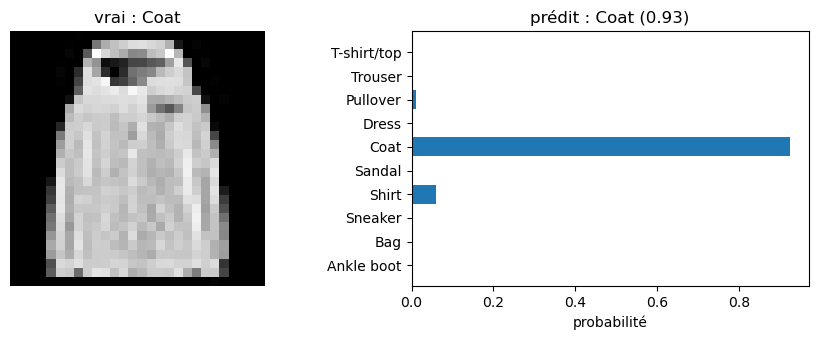

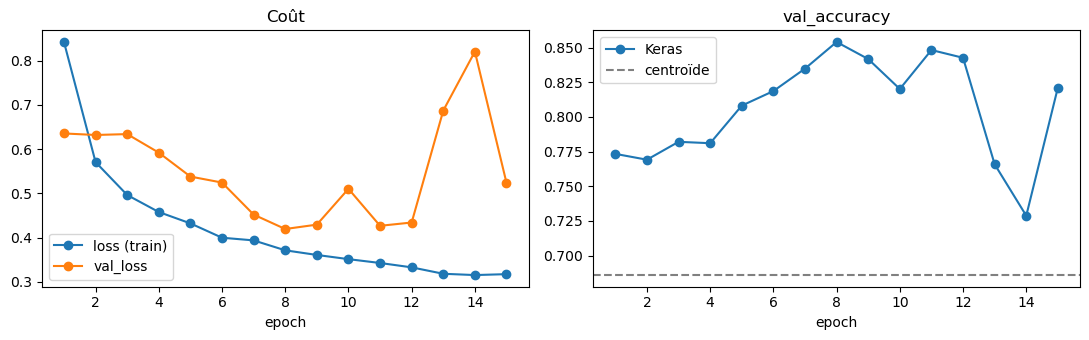

In [40]:
k_model.save("mlp_fashion.keras")
k_model2 = keras.saving.load_model("mlp_fashion.keras")
acc_reload = k_model2.evaluate(X_dev, y_dev, verbose=0)[1]     # doit être égal à celui de k_model et à acc_k
assert acc_reload == k_model.evaluate(X_dev, y_dev, verbose=0)[1]
i = 7
proba_k = keras.ops.convert_to_numpy(keras.ops.softmax(k_model2.predict(X_dev[i:i+1], verbose=0)))[0]   # (10,)
assert proba_k.shape == (10,) and abs(proba_k.sum() - 1) < 1e-5
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].imshow(X_dev[i].reshape(28, 28), cmap="gray"); ax[0].set_title(f"vrai : {CLASSES[y_dev[i]]}"); ax[0].axis("off")
ax[1].barh(CLASSES, proba_k); ax[1].invert_yaxis(); ax[1].set(title=f"prédit : {CLASSES[proba_k.argmax()]} ({proba_k.max():.2f})", xlabel="probabilité")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5)); ep = np.arange(1, len(h_k.history["loss"]) + 1)
ax[0].plot(ep, h_k.history["loss"], marker="o", label="loss (train)"); ax[0].plot(ep, h_k.history["val_loss"], marker="o", label="val_loss")
ax[0].set(title="Coût", xlabel="epoch"); ax[0].legend()
ax[1].plot(ep, h_k.history["val_accuracy"], marker="o", label="Keras"); ax[1].axhline(acc_centroide, color="gray", ls="--", label="centroïde")
ax[1].set(title="val_accuracy", xlabel="epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

### Tableau comparatif et courbes (fin du tronc commun)
Accuracy sur deux colonnes : la dernière epoch (ce que mesurent A, B et C) et la meilleure epoch (moins sensible au bruit, voir question 1). Complétez la colonne « lignes de code » en comptant vos lignes utiles (sans commentaires ni tests) pour définir et entraîner le modèle : NumPy ≈ 40, PyTorch ≈ 25, Keras ≈ 8.

,implémentation,accuracy dev (dernière epoch),accuracy dev (meilleure epoch),temps 15 epochs (s),lignes de code (à compléter)
0,NumPy,0.857,0.867,2.252,None
1,PyTorch,0.857,0.860,6.299,None
2,Keras,0.821,0.854,16.842,None


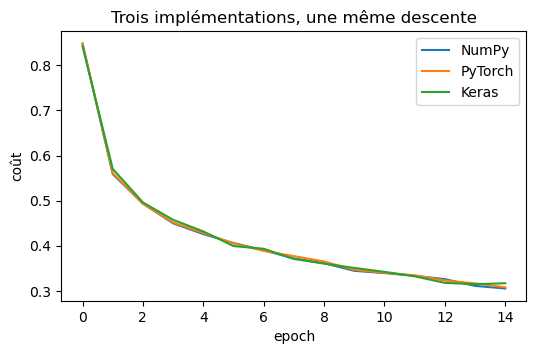

In [41]:
import pandas as pd
df_cmp = pd.DataFrame({"implémentation": ["NumPy", "PyTorch", "Keras"],
                       "accuracy dev (dernière epoch)": [acc_np, acc_pt, acc_k],
                       "accuracy dev (meilleure epoch)": [max(hist_np["acc_dev"]), max(hist_pt["acc_dev"]), acc_k_max],
                       "temps 15 epochs (s)": [time_np, time_pt, time_k],
                       "lignes de code (à compléter)": [None, None, None]})
display(df_cmp.round(3))
plt.figure(figsize=(6, 3.5)); plt.plot(hist_np["J"], label="NumPy"); plt.plot(hist_pt["J"], label="PyTorch")
if hist_k: plt.plot(hist_k, label="Keras")
plt.legend(); plt.xlabel("epoch"); plt.ylabel("coût"); plt.title("Trois implémentations, une même descente"); plt.show()

### Questions (à rédiger dans une cellule markdown, 5 lignes)
1. Les trois implémentations donnent-elles la même accuracy ? Pourquoi de petites différences sont-elles normales (initialisation, ordre des batchs, précision) ? Comparez les colonnes « dernière epoch » et « meilleure epoch » : avec SGD 0,1 sans momentum sur des pixels non centrés, l'accuracy dev oscille de ±5 points au fil des mini-batchs, donc un écart de 3 à 5 points entre deux « dernières epochs » est du bruit, pas une différence entre bibliothèques (à poids initiaux identiques et sans mélange, Keras et PyTorch donnent la même courbe à la précision flottante près). Deux remèdes que vous connaissez ou connaîtrez : centrer les entrées (J1 : entrées toutes positives ⇒ pour une unité donnée, toutes les pentes dW ont le même signe ⇒ la descente zigzague ; centrer les entrées supprime ce biais), le momentum (J5).
2. Pourquoi la dernière couche n'a-t-elle pas de softmax en PyTorch et en Keras ? Que se passerait-il si vous en mettiez un **en plus** de `CrossEntropyLoss` ?
3. Bonus GPU (Colab) : `hidden=(1024, 1024)`, mesurez le temps sur CPU puis sur GPU. Et sur le réseau 128-64 ?

---

# Pour ceux qui finissent en avance (2 h 45 de contenu supplémentaire)

Cinq parties indépendantes, à prendre dans l'ordre que vous voulez. Elles réutilisent vos fonctions des parties A et B. Rien n'est à rendre ; le corrigé est distribué en fin de TP et vous pouvez les terminer chez vous.

## Partie D — Les neuf pentes de ce matin, à la main puis avec autograd (30 min)

### D1. À la main en NumPy
Vérifiez vos gestes sur **l'appartement à neuf paramètres** de la slide : x = (2, 1), y = 5, `W1 = [[1, 1], [1, −1]]`, `b1 = 0`, `W2 = (1, 1)`, `b2 = 0`, sortie linéaire, erreur J = (ŷ − y)². Attendu : ŷ = 4, J = 1, puis dW2 = (−6, −2), db2 = −2, dW1 = [[−4, −2], [−4, −2]], db1 = (−2, −2). Même déroulé que `backward`, avec `dZ2 = 2 (ŷ − y)` au lieu de `AL − Y`.

In [42]:
x = np.array([[2.0], [1.0]]); y = 5.0
W1 = np.array([[1.0, 1.0], [1.0, -1.0]]); b1 = np.zeros((2, 1)); W2 = np.array([[1.0, 1.0]]); b2 = np.zeros((1, 1))
z1 = W1 @ x + b1; a1 = np.maximum(0, z1); y_hat = (W2 @ a1 + b2).item(); J = (y_hat - y) ** 2
assert np.isclose(y_hat, 4) and np.isclose(J, 1)
dZ2 = np.array([[2 * (y_hat - y)]])
dW2, db2 = dZ2 @ a1.T, dZ2.sum(axis=1, keepdims=True)
dA1 = W2.T @ dZ2; dZ1 = dA1 * (z1 > 0)
dW1, db1 = dZ1 @ x.T, dZ1.sum(axis=1, keepdims=True)
assert np.allclose(dW2, [[-6, -2]]) and np.allclose(db2, -2)
assert np.allclose(dW1, [[-4, -2], [-4, -2]]) and np.allclose(db1, [[-2], [-2]])
alpha = 0.01
W2n, b2n, W1n, b1n = W2 - alpha * dW2, b2 - alpha * db2, W1 - alpha * dW1, b1 - alpha * db1
y_hat2 = (W2n @ np.maximum(0, W1n @ x + b1n) + b2n).item(); J2 = (y_hat2 - y) ** 2
assert abs(y_hat2 - 4.47) < 0.01 and abs(J2 - 0.28) < 0.01
print(f"après une mise à jour : ŷ = {y_hat2:.3f}, J = {J2:.3f}")
PENTES_MATIN = dict(dW2=dW2, db2=db2, dW1=dW1, db1=db1)

après une mise à jour : ŷ = 4.470, J = 0.281


### D2. Autograd sur une parabole : J(w) = w² − 10w + 25
PyTorch calcule la passe arrière à partir de la seule passe avant : chaque tenseur créé avec `requires_grad=True` reçoit un `.grad` de sa propre forme après `loss.backward()`. Complétez la boucle : passe avant, `zero_grad`, `backward`, `step`. Au premier pas, `w.grad` doit valoir −10 (la dérivée 2w − 10 en w = 0).

In [43]:
w = torch.tensor(0.0, requires_grad=True)
opt = torch.optim.SGD([w], lr=0.01)
for step in range(1000):
    J = (w - 5) ** 2    # = w² - 10w + 25
    opt.zero_grad(); J.backward(); opt.step()
    if step == 0: assert torch.isclose(w.grad, torch.tensor(-10.0)), w.grad
print(w.item(), "attendu ≈ 5")

4.999988555908203 attendu ≈ 5


### D3. Les neuf pentes en une ligne
Refaites l'appartement de D1 avec des tenseurs : autograd doit retrouver exactement vos `PENTES_MATIN`.

In [44]:
xt = torch.tensor([[2.0], [1.0]]); yt_ = torch.tensor(5.0)
W1t = torch.tensor([[1.0, 1.0], [1.0, -1.0]], requires_grad=True); b1t = torch.zeros(2, 1, requires_grad=True)
W2t = torch.tensor([[1.0, 1.0]], requires_grad=True);             b2t = torch.zeros(1, requires_grad=True)
a1t = torch.relu(W1t @ xt + b1t); y_hat_t = W2t @ a1t + b2t; Jt = ((y_hat_t - yt_) ** 2).sum(); Jt.backward()
for name, g in [("dW2", W2t.grad), ("db2", b2t.grad), ("dW1", W1t.grad), ("db1", b1t.grad)]:
    assert g is not None and np.allclose(g.numpy().reshape(-1), np.asarray(PENTES_MATIN[name]).reshape(-1)), name

## Partie E — Un classifieur à 10 classes avec autograd, sans `nn.Module` (15 min)

Régression softmax (la régression logistique du TP1 à dix classes) : `W` (784, 10) et `b` (10,), convention framework `(m, 784)`. Vous n'écrivez **que la passe avant** ; `F.cross_entropy` prend les logits (le softmax est dans la perte). Cent pas de descente en batch complet (α = 0,1) suffisent pour voir la mécanique, et pour mesurer ce que vaut la couche cachée.

In [45]:
Xt20 = torch.tensor(X_train[:20000]); yt20 = torch.tensor(y_train[:20000], dtype=torch.long)
Xd_t = torch.tensor(X_dev); yd_t = torch.tensor(y_dev, dtype=torch.long)
W = torch.zeros(784, 10, requires_grad=True); b = torch.zeros(10, requires_grad=True)
opt = torch.optim.SGD([W, b], lr=0.1)
for e in range(100):
    logits = Xt20 @ W + b
    loss = F.cross_entropy(logits, yt20)
    opt.zero_grad(); loss.backward(); opt.step()
    if (e + 1) % 25 == 0:
        with torch.no_grad(): acc = ((Xd_t @ W + b).argmax(dim=1) == yd_t).float().mean().item()
        print(f"epoch {e+1:3d} | J {loss.item():.3f} | acc dev {acc:.4f}")
assert W.grad.shape == W.shape and b.grad.shape == b.shape

epoch  25 | J 1.004 | acc dev 0.6937
epoch  50 | J 0.833 | acc dev 0.7380
epoch  75 | J 0.756 | acc dev 0.7592
epoch 100 | J 0.709 | acc dev 0.7741


## Partie F — Expériences : initialisation, largeur, profondeur (40 min)

### F1. Initialisation (20 min)
1. **Initialisation à zéro** : entraînez 3 epochs le réseau NumPy avec `W = 0` (paramètre `init` de `train_np`). Que vaut l'accuracy ? Affichez trois lignes de `W1` : que remarquez-vous ? Expliquez avec le mot « symétrie ».
2. **Initialisation trop petite** : `W = N(0, 1) × 0,01` au lieu de He. Que devient la courbe de coût ?

In [46]:
def init_zero(layer_dims, seed=0):
    return {f"{n}{l}": np.zeros((layer_dims[l], layer_dims[l-1]) if n == "W" else (layer_dims[l], 1))
            for l in range(1, len(layer_dims)) for n in ("W", "b")}
def init_small(layer_dims, seed=0):
    rng = np.random.default_rng(seed); p = init_zero(layer_dims)
    for l in range(1, len(layer_dims)): p[f"W{l}"] = rng.standard_normal((layer_dims[l], layer_dims[l-1])) * 0.01
    return p

p0, h0 = train_np(Xtr, Ytr, Xdv, y_dev, dims, epochs=3, init=init_zero, verbose=False)
print("zéro : accuracy dev", h0["acc_dev"], "| 3 lignes de W1 (5 premières colonnes) :\n", p0["W1"][:3, :5])
assert h0["acc_dev"][-1] < 0.15          # à zéro, le réseau ne dépasse pas le hasard
_, h_small = train_np(Xtr, Ytr, Xdv, y_dev, dims, epochs=3, init=init_small, verbose=False)
_, h_he = train_np(Xtr, Ytr, Xdv, y_dev, dims, epochs=3, verbose=False)
print("coûts des 3 premières epochs : He", np.round(h_he["J"], 3), "| petit", np.round(h_small["J"], 3), "| zéro", np.round(h0["J"], 3))
print("accuracy dev à l'epoch 3 : He", round(h_he["acc_dev"][-1], 3), "| petit", round(h_small["acc_dev"][-1], 3))

zéro : accuracy dev [0.0954, 0.0954, 0.0954] | 3 lignes de W1 (5 premières colonnes) :
 [[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
coûts des 3 premières epochs : He [0.848 0.559 0.493] | petit [2.292 1.446 0.973] | zéro [2.303 2.303 2.303]
accuracy dev à l'epoch 3 : He 0.786 | petit 0.617


### F2. Largeur et profondeur (20 min)
Même boucle PyTorch, trois architectures, 8 epochs chacune : `hidden=(64,)`, `(128, 64)`, `(256, 128, 64)`. Tableau : nombre de paramètres, accuracy dev, temps. Le plus gros réseau est-il le meilleur ? (On reparlera de sur-apprentissage à J5.)

In [47]:
import pandas as pd
rows = []
for hidden in [(64,), (128, 64), (256, 128, 64)]:
    torch.manual_seed(0); mdl = MLP(hidden=hidden)
    t0 = time.perf_counter(); h = train_torch(mdl, train_loader, dev_loader, epochs=8, lr=0.1, verbose=False); dt = time.perf_counter() - t0
    rows.append({"architecture": str(hidden), "paramètres": sum(p.numel() for p in mdl.parameters()), "accuracy dev": h["acc_dev"][-1], "temps (s)": round(dt, 1)})
assert len(rows) == 3 and rows[1]["paramètres"] == 109_386
display(pd.DataFrame(rows))

,architecture,paramètres,accuracy dev,temps (s)
0,"(64,)",50890,0.8202,2.6
1,"(128, 64)",109386,0.8386,2.5
2,"(256, 128, 64)",242762,0.8216,3.0


#### F2 bis (optionnel) — La même expérience en Keras
Une fonction `keras_mlp(hidden)` qui construit et compile le `Sequential` de C1 pour une liste de largeurs, puis la même boucle sur les trois architectures (8 epochs, `verbose=0`). Vous devez retrouver les mêmes nombres de paramètres que ci-dessus, et des accuracy du même ordre.

In [48]:
def keras_mlp(hidden, n_in=784, n_out=10, lr=0.1):
    mdl = keras.Sequential([layers.Input((n_in,))] + [layers.Dense(h, activation="relu", kernel_initializer="he_normal") for h in hidden]
                           + [layers.Dense(n_out, kernel_initializer="he_normal")])
    mdl.compile(optimizer=keras.optimizers.SGD(lr), loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
    return mdl
rows_k = []
for hidden in [(64,), (128, 64), (256, 128, 64)]:
    keras.utils.set_random_seed(0); mdl = keras_mlp(hidden)
    t0 = time.perf_counter()
    h = mdl.fit(X_train[:20000], y_train[:20000], epochs=8, batch_size=128, validation_data=(X_dev, y_dev), verbose=0)
    rows_k.append({"architecture": str(hidden), "paramètres": mdl.count_params(), "accuracy dev": h.history["val_accuracy"][-1], "temps (s)": round(time.perf_counter() - t0, 1)})
df_k = pd.DataFrame(rows_k); display(df_k)
assert df_k["paramètres"].tolist() == [r["paramètres"] for r in rows]

,architecture,paramètres,accuracy dev,temps (s)
0,"(64,)",50890,0.8392,7.8
1,"(128, 64)",109386,0.8540,8.8
2,"(256, 128, 64)",242762,0.8418,10.0


## Partie G — Analyse des erreurs (25 min)

Avec le modèle PyTorch : matrice de confusion sur le dev, accuracy par classe triée, et huit erreurs affichées (vrai / prédit). Quelles paires de classes se confondent ? L'erreur est-elle « humaine » ? Rédigez trois lignes.

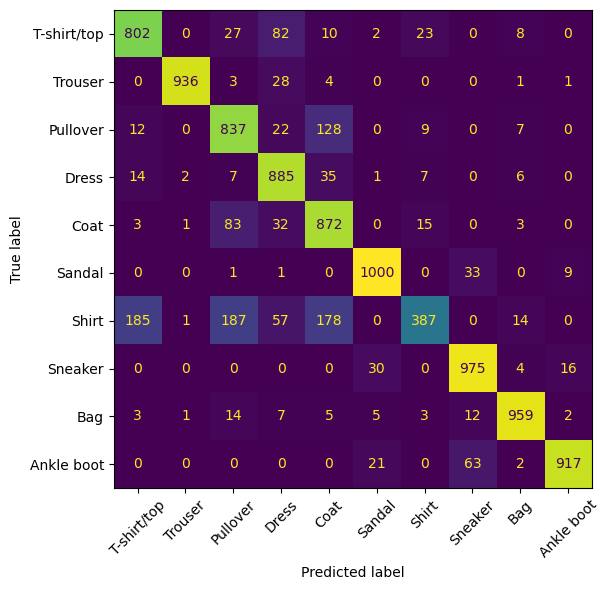

Shirt        0.384
Pullover     0.825
T-shirt/top  0.841
Coat         0.864
Ankle boot   0.914
Dress        0.925
Bag          0.949
Sneaker      0.951
Sandal       0.958
Trouser      0.962
confusion la plus fréquente : Shirt pris pour Pullover (187 fois)


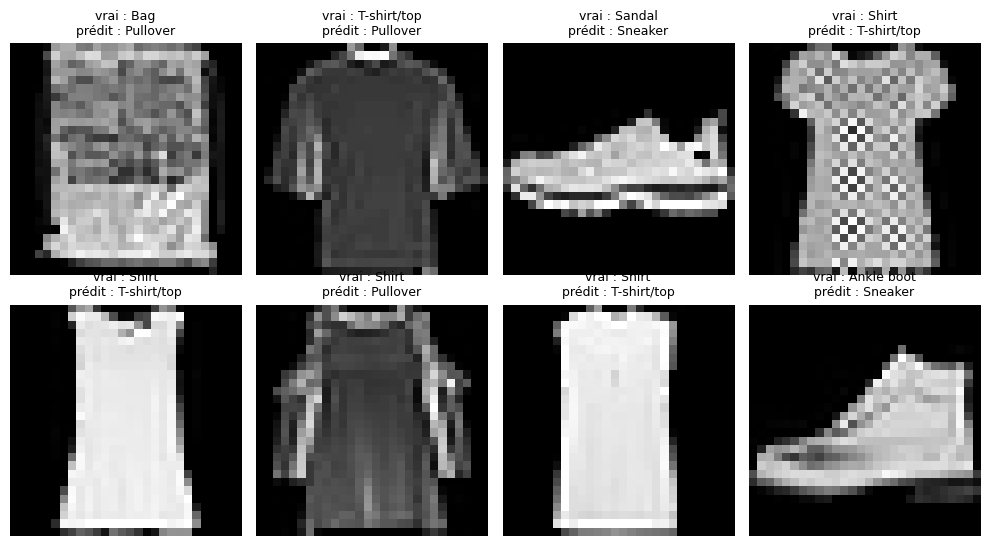

In [49]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
model.eval(); preds = []
with torch.no_grad():
    for xb, _ in dev_loader: preds.append(model(xb.to(device)).argmax(dim=1).cpu())
preds = torch.cat(preds).numpy()                  # (10 000,)
cm = confusion_matrix(y_dev, preds)
fig, ax = plt.subplots(figsize=(7, 6)); ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, xticks_rotation=45, colorbar=False); plt.tight_layout(); plt.show()
assert cm.shape == (10, 10) and cm.sum() == len(y_dev)
acc_classe = cm.diagonal() / cm.sum(axis=1)
for k in np.argsort(acc_classe): print(f"{CLASSES[k]:12s} {acc_classe[k]:.3f}")
hors_diag = cm.copy(); np.fill_diagonal(hors_diag, 0); vrai, pred_c = np.unravel_index(hors_diag.argmax(), hors_diag.shape)
print(f"confusion la plus fréquente : {CLASSES[vrai]} pris pour {CLASSES[pred_c]} ({hors_diag.max()} fois)")
erreurs = np.where(preds != y_dev)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(10, 5.5))
for a, j in zip(axes.ravel(), erreurs):
    a.imshow(X_dev[j].reshape(28, 28), cmap="gray"); a.set_title(f"vrai : {CLASSES[y_dev[j]]}\nprédit : {CLASSES[preds[j]]}", fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## Partie H — Premier pas vers le projet : un réseau qui prévoit la consommation (55 min)

Le projet du cours (présenté en fin de journée) : prévoir la **consommation électrique française** des 24 prochaines heures. Avec exactement les outils de la partie B, construisez un premier réseau de **régression** : entrée = les 168 dernières heures (une semaine), sortie = **24 valeurs** en MW, perte = erreur quadratique, sortie **linéaire** (pas de softmax : on prédit des nombres). On compare à la baseline « même heure la veille ». À J3 vous ajouterez la température et le calendrier, et le protocole d'évaluation complet.

Le fichier `conso_france_horaire.csv` doit être dans `data/` (sur Colab : `from google.colab import files; files.upload()`).

In [51]:
import pandas as pd, os
CANDIDATS = ["data/conso_france_horaire.csv", "../projet/data/conso_france_horaire.csv", "../../projet/data/conso_france_horaire.csv", "conso_france_horaire.csv"]
path = next((p for p in CANDIDATS if os.path.exists(p)), None)
assert path, "conso_france_horaire.csv introuvable : copiez le fichier du projet dans data/"
dfc = pd.read_csv(path)
dfc["datetime"] = pd.to_datetime(dfc["datetime"], utc=True).dt.tz_convert("Europe/Paris")
conso = dfc["consommation_mw"].to_numpy("float32")           # 113 976 heures, en MW

# Une fenêtre par jour, prise à minuit : entrée = les 168 h précédentes, cible = les 24 h qui suivent.
H_IN, H_OUT = 168, 24
minuits = np.where(dfc["datetime"].dt.hour.to_numpy() == 0)[0]
minuits = minuits[(minuits >= H_IN) & (minuits + H_OUT <= len(conso))]
Xw = np.stack([conso[t - H_IN:t] for t in minuits]); Yw = np.stack([conso[t:t + H_OUT] for t in minuits])      # (jours, 168), (jours, 24)
annee = dfc["datetime"].dt.year.to_numpy()[minuits]
tr, dv = annee <= 2022, annee == 2023                         # 2024 reste intouché : c'est l'année du protocole d'évaluation du projet
mu_c, sd_c = conso[: minuits[tr][-1]].mean(), conso[: minuits[tr][-1]].std()      # standardisation calculée sur le train seulement (J1)
Xw_s, Yw_s = (Xw - mu_c) / sd_c, (Yw - mu_c) / sd_c
mae_veille = np.abs(Xw[dv][:, -24:] - Yw[dv]).mean()          # baseline : « la même heure que la veille » = les 24 dernières heures de l'entrée
print(f"{tr.sum()} jours de train (2012-2022), {dv.sum()} jours de dev (2023) | baseline veille : MAE = {mae_veille:,.0f} MW")

4011 jours de train (2012-2022), 365 jours de dev (2023) | baseline veille : MAE = 2,592 MW


### H1. Le réseau de régression
`MLP(n_in=168, hidden=(128, 64), n_out=24)` : la même classe qu'en B1, sortie linéaire. Perte `nn.MSELoss()`, optimiseur Adam (présenté à J5 : acceptez-le pour l'instant comme un SGD qui règle son pas tout seul), 30 epochs, batch 64. Mesurez la MAE dev **en MW** (après dé-standardisation) et comparez à la baseline.

In [52]:
Xw_t, Yw_t = torch.tensor(Xw_s), torch.tensor(Yw_s)
tl = DataLoader(TensorDataset(Xw_t[tr], Yw_t[tr]), batch_size=64, shuffle=True)
reg = MLP(n_in=168, hidden=(128, 64), n_out=24).to(device)
opt = torch.optim.Adam(reg.parameters(), lr=1e-3); loss_fn = nn.MSELoss()
for e in range(30):
    reg.train()
    for xb, yb in tl:
        xb, yb = xb.to(device), yb.to(device)
        loss = loss_fn(reg(xb), yb); opt.zero_grad(); loss.backward(); opt.step()
def mae_mw(model):
    model.eval()
    with torch.no_grad(): pred = model(Xw_t[dv].to(device)).cpu().numpy() * sd_c + mu_c      # retour en MW
    return np.abs(pred - Yw[dv]).mean(), pred
mae_mlp, pred_dv = mae_mw(reg)
assert mae_mlp is not None and mae_mlp < mae_veille and pred_dv.shape == Yw[dv].shape
print(mae_mlp, "MW contre la baseline veille", mae_veille)

1463.7686 MW contre la baseline veille 2591.5923


### H2. Regarder une semaine de prévisions
Tracez, pour une semaine de janvier 2023, la vérité, la baseline veille et le réseau. Où le réseau se trompe-t-il le plus (week-end ? vague de froid ?) ? C'est la question que vous poserez à chaque modèle du projet.

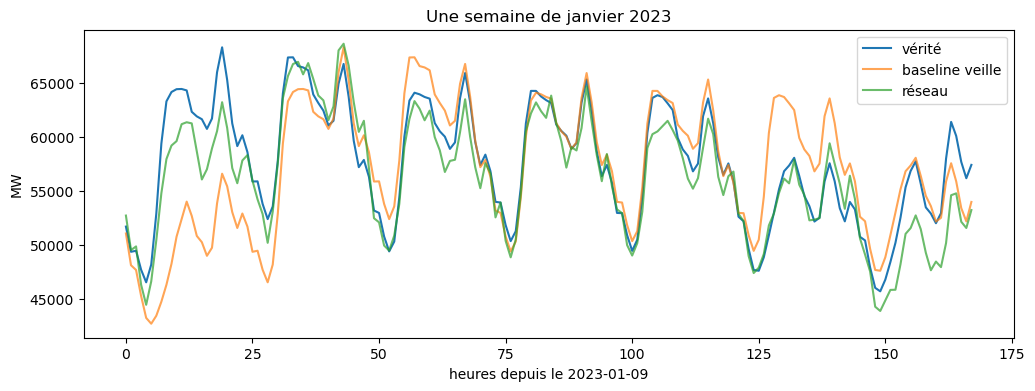

pire jour : 2023-04-17 (Monday) | MAE réseau 4,481 MW | baseline 5,446 MW
pire jour : 2023-08-21 (Monday) | MAE réseau 3,989 MW | baseline 5,788 MW
pire jour : 2023-01-15 (Sunday) | MAE réseau 3,775 MW | baseline 2,031 MW


In [53]:
jours_dv = dfc["datetime"].iloc[minuits[dv]].dt.date.to_numpy()
veille_dv = Xw[dv][:, -24:]
i0 = next(i for i, d in enumerate(jours_dv) if d.year == 2023 and d.month == 1 and d.day >= 9)      # un lundi de janvier 2023 si possible
sl = slice(i0, i0 + 7)
plt.figure(figsize=(12, 4))
plt.plot(Yw[dv][sl].ravel(), label="vérité"); plt.plot(veille_dv[sl].ravel(), label="baseline veille", alpha=0.7); plt.plot(pred_dv[sl].ravel(), label="réseau", alpha=0.7)
plt.xlabel(f"heures depuis le {jours_dv[i0]}"); plt.ylabel("MW"); plt.legend(); plt.title("Une semaine de janvier 2023"); plt.show()
err_jour = np.abs(pred_dv - Yw[dv]).mean(axis=1)          # MAE par jour du dev
for j in np.argsort(err_jour)[::-1][:3]: print(f"pire jour : {jours_dv[j]} ({jours_dv[j]:%A}) | MAE réseau {err_jour[j]:,.0f} MW | baseline {np.abs(veille_dv[j] - Yw[dv][j]).mean():,.0f} MW")
assert len(err_jour) == dv.sum()

### H3. La même régression en Keras (15 min)
`Sequential` 168 → 128 → 64 → 24 avec sortie **linéaire**, `compile(optimizer=Adam, loss="mse", metrics=["mae"])`, 30 epochs, batch 64, sur les mêmes tableaux standardisés. Mesurez la MAE dev en MW après dé-standardisation et comparez-la à la version PyTorch (H1) et à la baseline veille. Les deux réseaux sont le même modèle : un écart de quelques centaines de MW entre deux runs est la variance normale d'un entraînement de 30 epochs sur 4 000 jours (relancez H1 avec une autre graine pour vous en convaincre : mettez `torch.manual_seed(1)` en tête de H1) ; à J3, le protocole à trois plis du projet lissera cela.

In [54]:
keras.utils.set_random_seed(0)
k_reg = keras.Sequential([layers.Input((H_IN,)),
                          layers.Dense(128, activation="relu", kernel_initializer="he_normal"),
                          layers.Dense(64, activation="relu", kernel_initializer="he_normal"),
                          layers.Dense(H_OUT, kernel_initializer="he_normal")])
k_reg.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
assert k_reg.count_params() == sum(p.numel() for p in reg.parameters())
k_reg.fit(Xw_s[tr], Yw_s[tr], epochs=30, batch_size=64, validation_data=(Xw_s[dv], Yw_s[dv]), verbose=0)
pred_k = k_reg.predict(Xw_s[dv], verbose=0) * sd_c + mu_c
mae_k_reg = np.abs(pred_k - Yw[dv]).mean()
assert mae_k_reg < mae_veille
print(mae_k_reg, "MW (Keras) contre", mae_mlp, "MW (PyTorch) et la baseline veille", mae_veille)

1177.5465 MW (Keras) contre 1463.7686 MW (PyTorch) et la baseline veille 2591.5923


## Ce que contient votre notebook en fin de séance
**Tronc commun (2 h 05)** : cinq fonctions NumPy testées par des `assert` et un réseau à ~86 % dev (A) ; le même réseau en PyTorch, sauvegardé, rechargé, une image prédite (B) ; le même en Keras, sauvegardé, rechargé, la même image prédite et `history` tracé (C) ; le tableau comparatif (dernière et meilleure epoch), les courbes et les réponses aux questions.

**Pour ceux qui finissent en avance** : les neuf pentes de l'appartement à la main puis par autograd (D) ; un classifieur softmax sans `nn.Module` (E) ; les expériences d'initialisation, de largeur et de profondeur, en PyTorch puis en Keras (F) ; la matrice de confusion et huit erreurs commentées (G) ; un premier réseau de régression sur la consommation électrique en PyTorch puis en Keras, sa MAE en MW contre la baseline veille et une semaine tracée (H).

Le corrigé est distribué en fin de TP ; rien n'est à rendre. Gardez vos fonctions `MLP`, `evaluate` et `train_torch` : elles resserviront à J3 et dans le projet.